# Analyse du data drift — Étape 3

**Objectif.** Vérifier si les clients qui arrivent en production ressemblent encore à ceux sur
lesquels le modèle a été entraîné. S'ils s'en éloignent (*data drift*), les prédictions peuvent
se dégrader sans qu'aucune erreur ne soit visible : l'API continue de répondre normalement.

**Pourquoi surveiller les données et pas directement la performance ?** En crédit, on ne sait si
un client rembourse que des mois après la décision. En attendant ces vraies étiquettes, la dérive
des données d'entrée est le **signal d'alerte précoce** disponible.

**Les deux jeux comparés**
| Jeu | Source | Rôle |
|---|---|---|
| Référence | Clients d'entraînement du projet 6 (`application_train`) | Ce que le modèle « connaît » |
| Production | Clients de `application_test`, envoyés un par un à l'API et journalisés en base | Ce qui arrive réellement |

**Plan**
1. Choisir les variables surveillées
2. Préparer les données de référence et de production
3. Charger les données comparées
4. Tests statistiques par type de variable et PSI
5. Visualisations et rapport Evidently
6. Sortie du modèle et analyse opérationnelle
7. Suivi dans le temps et scénario de production dégradée
8. Conclusion et plan d'action

## 1. Les variables surveillées

Le modèle utilise 800 variables. Les surveiller toutes serait illisible. On suit les variables qui **pèsent le plus dans les décisions** :
une dérive sur l'une d'elles a un impact direct sur les scores.

La liste est calculée par `ModeleScoring.variables_surveillees()` : l'API (qui ne journalise que
ces 12 variables) et ce notebook utilisent ainsi exactement la même définition.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RACINE = Path.cwd().parent        # le notebook est dans notebooks/ : la racine du projet est juste au-dessus
sys.path.append(str(RACINE))      # permet d'importer le code de l'API comme un module
from api.modele import ModeleScoring, lire_signature

modele = ModeleScoring()          # le MÊME modèle que l'API, empreinte SHA-256 vérifiée au chargement

### Mesurer l'importance : le *gain* plutôt que le *split*

LightGBM propose deux mesures :
- **split** : le nombre de fois où une variable sert à couper un arbre ;
- **gain** : de combien ces coupures ont réellement réduit l'erreur.

Une variable peut être utilisée très souvent pour des coupures marginales (beaucoup de *splits*,
peu de gain). Le gain mesure donc mieux ce qui **compte vraiment dans la décision** : c'est
la mesure retenue, déjà utilisée au projet 6 pour le graphique d'importance.


In [2]:
# Importance par "gain" : combien chaque variable a réellement fait baisser l'erreur du modèle
importances = pd.Series(
    modele.modele.booster_.feature_importance(importance_type="gain"),
    index=modele.variables,
).sort_values(ascending=False)

part = importances / importances.sum() * 100                     # en % du gain total : plus lisible
TYPES = {v["name"]: v["type"] for v in lire_signature()}          # double / long / boolean, lu dans MLmodel

TOP10 = part.head(10).index.tolist()
print(f"Le top 10 pèse {part.head(10).sum():.0f} % du gain total, sur {len(part)} variables")
pd.DataFrame({"part_gain_%": part.head(15).round(2),
              "type": [TYPES[c] for c in part.head(15).index]})


Le top 10 pèse 45 % du gain total, sur 800 variables


,part_gain_%,type
EXT_SOURCE_3,16.00,double
EXT_SOURCE_2,13.56,double
EXT_SOURCE_1,4.48,double
PAYMENT_RATE,2.92,double
DAYS_EMPLOYED,2.04,double
DAYS_BIRTH,1.47,long
INSTAL_DPD_MEAN,1.39,double
AMT_ANNUITY,1.18,double
CC_CNT_DRAWINGS_ATM_CURRENT_MEAN,0.99,double
APPROVED_CNT_PAYMENT_MEAN,0.98,double


**Lecture.** L'importance est très concentrée : 10 variables sur 800 portent **45 %** du gain
total, et les trois scores externes `EXT_SOURCE_1/2/3` en portent à eux seuls **34 %**.
Ce sont les variables à surveiller en priorité : si ces scores, fournis par des organismes
extérieurs, changent de méthode de calcul, le modèle dérive sans que rien ne change chez nous.

Toutes les variables du top 10 sont **numériques** (`double` ou `long`).


['EXT_SOURCE_3',
 'EXT_SOURCE_2',
 'EXT_SOURCE_1',
 'PAYMENT_RATE',
 'DAYS_EMPLOYED',
 'DAYS_BIRTH',
 'INSTAL_DPD_MEAN',
 'AMT_ANNUITY',
 'CC_CNT_DRAWINGS_ATM_CURRENT_MEAN',
 'APPROVED_CNT_PAYMENT_MEAN',
 'NAME_EDUCATION_TYPE_Higher_education',
 'CODE_GENDER_F']

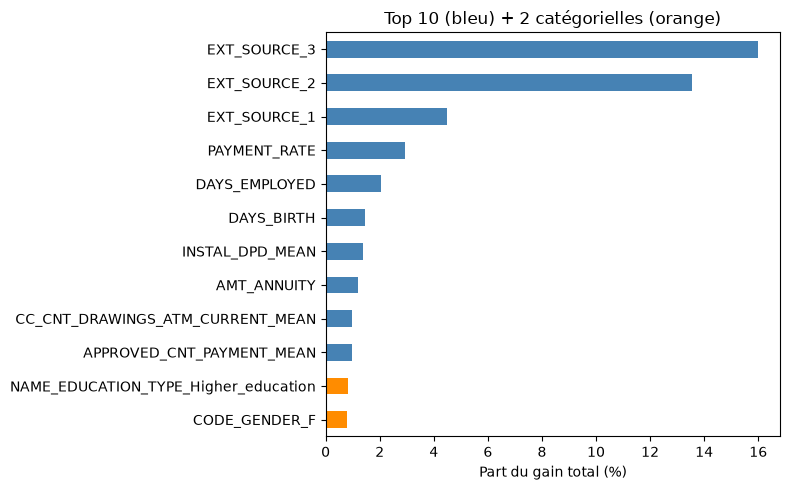

In [3]:
# Le top 10 est 100 % numérique : on ajoute les 2 variables 0/1 (issues du one-hot) les mieux classées
VARIABLES_SUIVIES = modele.variables_surveillees()   # la même liste que celle journalisée par l'API

top = part[VARIABLES_SUIVIES].sort_values()                       # tri croissant : la plus importante en haut du barh
couleurs = ["darkorange" if TYPES[c] == "boolean" else "steelblue" for c in top.index]
fig, ax = plt.subplots(figsize=(8, 5))
top.plot.barh(ax=ax, color=couleurs)
ax.set_xlabel("Part du gain total (%)")
ax.set_title("Top 10 (bleu) + 2 catégorielles (orange)")
fig.tight_layout()
VARIABLES_SUIVIES


**Pourquoi ajouter deux variables catégorielles ?** Le test de drift dépend du type de variable :
Kolmogorov-Smirnov pour les numériques, chi² pour les catégorielles. Le top 10 étant 100 %
numérique, on ajoute les deux variables 0/1 (issues du one-hot du projet 6) les mieux classées :
`NAME_EDUCATION_TYPE_Higher_education` (13e) et `CODE_GENDER_F` (15e).

**Point de vigilance : le genre.** Surveiller la répartition hommes/femmes en production est
sans risque au regard du RGPD : on compare des **proportions agrégées**, aucune donnée
individuelle n'est exposée. En revanche, le fait que le **modèle lui-même** utilise le genre
pour décider d'un crédit pose une question d'équité (risque de discrimination).

**Variables surveillées : 12** (10 numériques + 2 catégorielles), conservées dans `VARIABLES_SUIVIES`.


## 2. Les données de référence et de production

Préparées par `scripts/preparer_donnees.py`, qui reproduit à l'identique la préparation du projet 6
(table principale + agrégats des 5 tables d'historique, 800 variables).

- **Référence** (`data/reference.parquet`, 246 008 clients) : le `X_train` du projet 6, retrouvé
  grâce au même découpage (`test_size=0.2`, `stratify`, `random_state=42`). Contrôle : les
  probabilités des 3 premiers clients sont identiques à celles du projet 6 (0,0487 · 0,0807 · 0,1983).
- **Production** (`data/production.parquet`, 48 744 clients) : `application_test`, des clients que
  le modèle n'a jamais vus et dont on ne connaît pas l'issue (pas de colonne `TARGET`).

**Pourquoi préparer les deux jeux ensemble ?** L'encodage one-hot ne crée une colonne que pour les
catégories présentes. Trois catégories n'existent que dans le train (`CODE_GENDER = XNA`,
`NAME_INCOME_TYPE = Maternity leave`, `NAME_FAMILY_STATUS = Unknown`) : préparé seul, le jeu de
production n'aurait pas ces colonnes et l'API refuserait chaque client. En production réelle, où
les clients arrivent un par un, on alignerait chaque client sur la liste des variables du modèle.


## 3. Les données comparées

- **Référence** : les 12 variables surveillées des 246 008 clients d'entraînement (`data/reference.parquet`).
- **Production** : les appels journalisés par l'API dans `logs/appels.db`, remplis par
  `scripts/simuler_production.py` (5 000 clients de `application_test`, dont 2 % de requêtes
  rendues invalides exprès pour l'analyse opérationnelle). Seules les prédictions réussies (statut 200)
  servent à l'analyse du drift : les requêtes refusées n'ont pas d'entrées enregistrées.


In [4]:
reference = pd.read_parquet(RACINE / "data" / "reference.parquet", columns=VARIABLES_SUIVIES)

appels = pd.read_sql_table("appels", f"sqlite:///{RACINE / 'logs' / 'appels.db'}")
predictions = appels[appels["statut_http"] == 200]
production = pd.DataFrame(predictions["entrees"].tolist(), index=predictions.index)   # 1 colonne par variable

assert list(production.columns) == list(reference.columns) == VARIABLES_SUIVIES      # mêmes variables, même ordre
reference, production = reference.astype(float), production.astype(float)          # booléens → 0/1, None → NaN
print(f"Référence : {len(reference):,} clients | Production : {len(production):,} prédictions "
      f"(+ {len(appels) - len(production)} appels refusés, analysés à la section 6)")


Référence : 246,008 clients | Production : 4,912 prédictions (+ 88 appels refusés, analysés à la section 6)


In [5]:
pd.DataFrame({
    "moyenne_référence": reference.mean(),
    "moyenne_production": production.mean(),
    "manquants_référence_%": reference.isna().mean() * 100,
    "manquants_production_%": production.isna().mean() * 100,
}).round(3)

,moyenne_référence,moyenne_production,manquants_référence_%,manquants_production_%
EXT_SOURCE_3,0.511,0.494,19.839,17.793
EXT_SOURCE_2,0.514,0.516,0.216,0.000
EXT_SOURCE_1,0.502,0.504,56.338,42.732
PAYMENT_RATE,0.054,0.066,0.004,0.061
DAYS_EMPLOYED,-2384.994,-2506.666,17.944,18.750
DAYS_BIRTH,-16029.516,-16160.609,0.000,0.000
INSTAL_DPD_MEAN,1.058,0.729,5.159,1.547
AMT_ANNUITY,27108.090,29377.131,0.004,0.061
CC_CNT_DRAWINGS_ATM_CURRENT_MEAN,0.567,0.416,80.074,76.792
APPROVED_CNT_PAYMENT_MEAN,13.595,13.540,5.685,2.158


## 4. Tests statistiques par type de variable

| Type | Test (« la distribution a-t-elle changé ? ») | Mesure de taille (« de combien ? ») |
|---|---|---|
| Numérique (10) | Kolmogorov-Smirnov, dérive si p < 0,05 | Wasserstein normalisée par l'écart-type |
| Catégorielle 0/1 (2) | Chi², dérive si p < 0,05 | Divergence de Jensen-Shannon |
| Toutes | — | **PSI** : < 0,1 stable · 0,1 à 0,25 à surveiller · > 0,25 critique |

Avec 246 008 clients en référence, les tests détectent des écarts minuscules sans importance pratique :
la décision s'appuie donc sur le **PSI**, et la p-value sert de complément.
On suit aussi l'**évolution du taux de valeurs manquantes**, que les tests ignorent (ils travaillent
sans les NaN), alors qu'un saut brutal est un signe classique de problème technique.


In [6]:
import numpy as np


def calculer_psi(reference, production, n_tranches=10):
    """PSI d'une variable : < 0,1 stable · 0,1 à 0,25 à surveiller · > 0,25 dérive critique."""
    ref, prod = reference.dropna(), production.dropna()
    if ref.nunique() <= 2:
        # Variable 0/1 : une tranche par valeur (des déciles tomberaient tous sur 0 ou 1 → une seule tranche)
        valeurs = sorted(ref.unique())
        part_ref = ref.value_counts(normalize=True).reindex(valeurs).to_numpy()
        part_prod = prod.value_counts(normalize=True).reindex(valeurs, fill_value=0).to_numpy()
    else:
        # Variable numérique : tranches de 10 % des clients de RÉFÉRENCE (déciles)
        bornes = np.unique(np.quantile(ref, np.linspace(0, 1, n_tranches + 1)))
        bornes[0], bornes[-1] = -np.inf, np.inf          # les valeurs hors bornes tombent dans la 1re/dernière tranche
        part_ref = np.histogram(ref, bins=bornes)[0] / len(ref)
        part_prod = np.histogram(prod, bins=bornes)[0] / len(prod)
    part_ref = np.clip(part_ref, 1e-6, None)             # évite log(0) si une tranche est vide
    part_prod = np.clip(part_prod, 1e-6, None)
    return float(np.sum((part_prod - part_ref) * np.log(part_prod / part_ref)))


# La fonction se vérifie elle-même : 0 sur deux jeux identiques, alerte sur une 0/1 très déséquilibrée
assert calculer_psi(reference["EXT_SOURCE_2"], reference["EXT_SOURCE_2"]) < 1e-9
assert calculer_psi(reference["CODE_GENDER_F"], pd.Series([0.0] * 90 + [1.0] * 10)) > 0.25


In [7]:
from scipy.spatial.distance import jensenshannon
from scipy.stats import chi2_contingency, ks_2samp, wasserstein_distance


def tester_variable(reference, production, categorielle):
    """Test adapté au type de la variable, mesure de taille, PSI et évolution des manquants."""
    ref, prod = reference.dropna(), production.dropna()   # les tests scipy n'acceptent pas les NaN
    if categorielle:
        # Effectifs : une ligne par valeur (0, 1), une colonne par jeu
        comptes = pd.DataFrame({"reference": ref.value_counts(), "production": prod.value_counts()}).fillna(0)
        _, p_value, _, _ = chi2_contingency(comptes)      # 4 résultats : on ne garde que la p-value
        proportions = comptes / comptes.sum()
        test, distance = "chi²", jensenshannon(proportions["reference"], proportions["production"])
    else:
        _, p_value = ks_2samp(ref, prod)
        test, distance = "KS", wasserstein_distance(ref, prod) / ref.std()   # sans unité : comparable entre variables
    return {
        "test": test,
        "p_value": p_value,
        "distance": distance,
        "psi": calculer_psi(reference, production),
        "ecart_manquants_pts": (production.isna().mean() - reference.isna().mean()) * 100,
    }


resultats = pd.DataFrame(
    [tester_variable(reference[nom], production[nom], TYPES[nom] == "boolean") for nom in VARIABLES_SUIVIES],
    index=VARIABLES_SUIVIES,
)
resultats["drift_test"] = resultats["p_value"] < 0.05
resultats["statut_psi"] = pd.cut(resultats["psi"], [-np.inf, 0.1, 0.25, np.inf],
                                 labels=["stable", "à surveiller", "critique"])
resultats.round(4)


,test,p_value,distance,psi,ecart_manquants_pts,drift_test,statut_psi
EXT_SOURCE_3,KS,0.0000,0.0913,0.0129,-2.0456,True,stable
EXT_SOURCE_2,KS,0.0101,0.0472,0.0134,-0.2158,True,stable
EXT_SOURCE_1,KS,0.0082,0.0410,0.0085,-13.6055,True,stable
PAYMENT_RATE,KS,0.0000,0.5668,1.4657,0.0570,True,critique
DAYS_EMPLOYED,KS,0.0004,0.0536,0.0076,0.8063,True,stable
DAYS_BIRTH,KS,0.0116,0.0319,0.0046,0.0000,True,stable
INSTAL_DPD_MEAN,KS,0.0000,0.0423,0.0102,-3.6115,True,stable
AMT_ANNUITY,KS,0.0000,0.1577,0.0347,0.0570,True,stable
CC_CNT_DRAWINGS_ATM_CURRENT_MEAN,KS,0.0000,0.1737,0.0439,-3.2827,True,stable
APPROVED_CNT_PAYMENT_MEAN,KS,0.1022,0.0293,0.0049,-3.5268,False,stable


In [8]:
r, p = reference["PAYMENT_RATE"], production["PAYMENT_RATE"]
display(pd.DataFrame({"référence": r.describe(), "production": p.describe()}).round(4))

# 1 / PAYMENT_RATE ≈ durée du crédit en années : une lecture que le métier comprend directement
durees = [0, 10, 15, 19.9, 20.1, 25, np.inf]
etiquettes = ["< 10 ans", "10-15 ans", "15-20 ans", "20 ans pile (renouvelables)", "20-25 ans", "> 25 ans"]
pd.DataFrame({
    "référence_%": pd.cut(1 / r, durees, labels=etiquettes).value_counts(normalize=True, sort=False),
    "production_%": pd.cut(1 / p, durees, labels=etiquettes).value_counts(normalize=True, sort=False),
}).mul(100).round(1)


,référence,production
count,245998.0000,4909.0000
mean,0.0537,0.0664
std,0.0225,0.0247
min,0.0221,0.0310
25%,0.0369,0.0483
50%,0.0500,0.0580
75%,0.0639,0.0794
max,0.1244,0.1244


,référence_%,production_%
PAYMENT_RATE,,
< 10 ans,6.4,16.2
10-15 ans,16.5,26.5
15-20 ans,18.6,29.9
20 ans pile (renouvelables),9.5,0.8
20-25 ans,16.9,14.4
> 25 ans,32.1,12.2


### Interprétation

**Tests et PSI ne disent pas la même chose.** Le test signale une dérive sur 11 variables sur 12, le PSI
sur une seule. Avec 246 008 clients en référence, la moindre différence devient « significative » :
c'est le PSI qui mesure si l'écart compte.

**`PAYMENT_RATE` : dérive critique (PSI 1,47), changement réel de la population.**
`PAYMENT_RATE` = annuité ÷ montant du crédit. Le montant demandé baisse (médiane −13 %) davantage que
l'annuité, qui augmente légèrement (médiane +5 %) : les crédits sont plus courts. Les crédits de plus
de 25 ans passent de 32 % à 12 % des demandes, ceux de moins de 15 ans de 23 % à 43 %, et les crédits
renouvelables (`PAYMENT_RATE` toujours égal à 0,05) de 9,5 % à 0,8 %.
Ce n'est pas un bug mais un changement de l'offre ou de la demande. `AMT_CREDIT` n'étant pas surveillée,
seule la variable construite a permis de le voir : surveiller les variables utilisées par le modèle, et
pas seulement les données brutes, est indispensable.

**`EXT_SOURCE_1` : distribution stable, mais 13,6 points de valeurs manquantes en moins.**
Les valeurs renseignées gardent la même distribution (PSI 0,009) : la source externe couvre
simplement plus de clients. Ce n'est pas neutre pour le modèle : à l'entraînement, l'absence de cette
donnée signalait un risque plus élevé (8,5 % de défaut contre 7,5 %), et LightGBM l'a appris. Les
clients désormais renseignés voient donc leur score changer. Triage : changement de collecte, à
confirmer avec le fournisseur, à prendre en compte au prochain réentraînement.

**Conclusion provisoire** : une dérive critique sur la 4e variable du modèle justifie une alerte.
Reste à savoir si elle dégrade les décisions : c'est l'objet de la section 6 (distribution des scores)
et du plan d'action.


## 5. Visualiser la dérive

Les tests donnent un chiffre par variable ; les graphiques montrent **où** la distribution a bougé.

- **Histogrammes superposés**, avec les mêmes tranches pour la référence et la production, et en
  densité (l'aire vaut 1) pour comparer 246 008 clients à 4 912. L'axe est limité aux valeurs
  comprises entre le 1er et le 99e centile de la référence, sinon quelques valeurs extrêmes écrasent le graphique.
- **Écart de corrélation** : si les liens entre variables changent, le modèle, qui les a appris,
  peut se tromper même quand chaque variable prise seule paraît stable.
- **Rapport Evidently** : la même analyse, produite par un outil standard, en page HTML consultable
  sans Python.


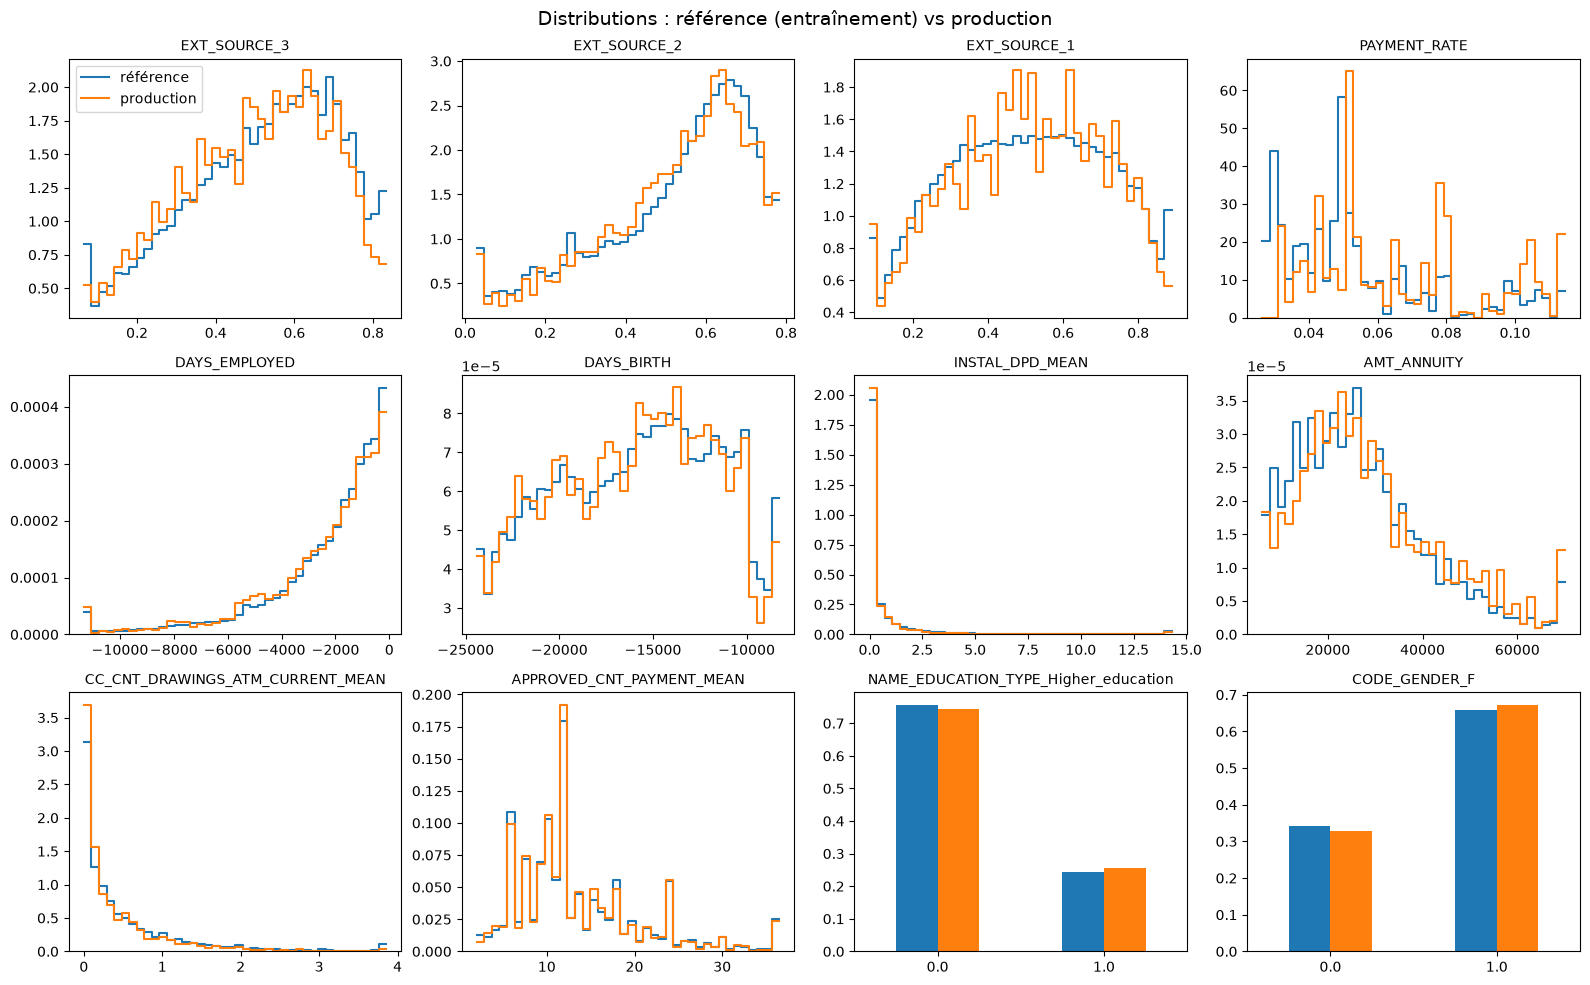

In [9]:
import seaborn as sns

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for nom, ax in zip(VARIABLES_SUIVIES, axes.flat):
    if TYPES[nom] == "boolean":
        # Variable 0/1 : la part de chaque valeur, côte à côte
        parts = pd.DataFrame({"référence": reference[nom].value_counts(normalize=True),
                              "production": production[nom].value_counts(normalize=True)}).sort_index()
        parts.plot.bar(ax=ax, rot=0, color=["tab:blue", "tab:orange"], legend=False)
    else:
        bas, haut = reference[nom].quantile([0.01, 0.99])
        tranches = np.linspace(bas, haut, 41)           # 40 tranches, LES MÊMES pour les deux jeux
        for donnees, etiquette in [(reference, "référence"), (production, "production")]:
            sns.histplot(donnees[nom].clip(bas, haut), bins=tranches, stat="density",
                         element="step", fill=False, ax=ax, label=etiquette)
    ax.set_title(nom, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
axes.flat[0].legend()
fig.suptitle("Distributions : référence (entraînement) vs production", fontsize=14)
fig.tight_layout()


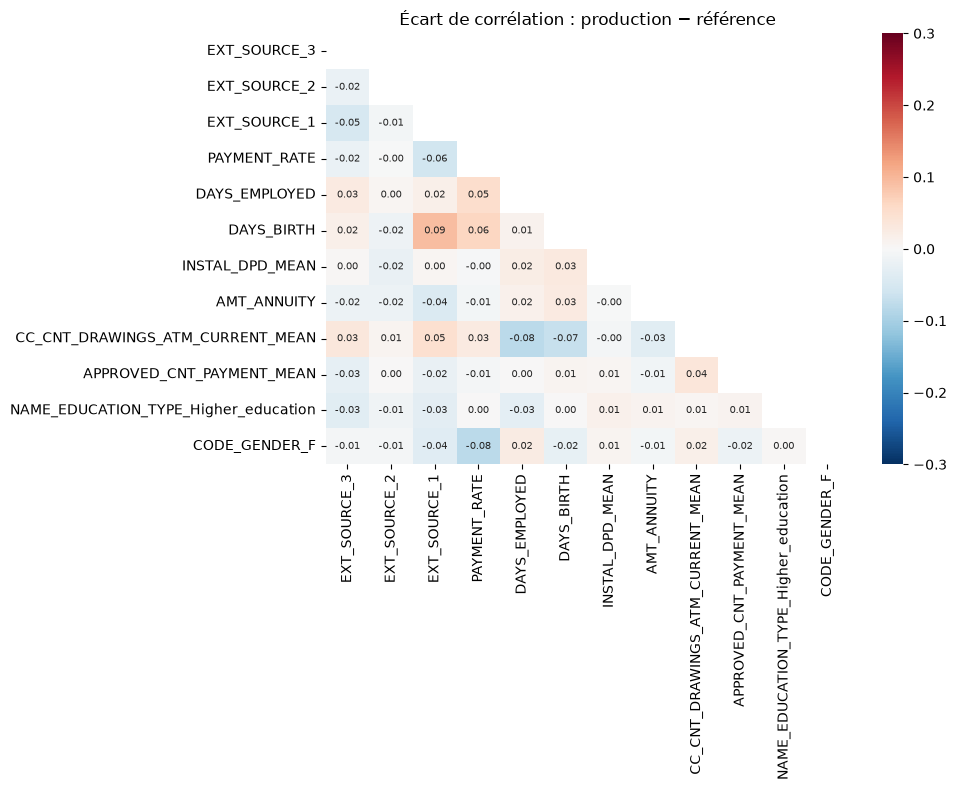

In [10]:
ecart = production.corr() - reference.corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(ecart, mask=np.triu(np.ones(ecart.shape, dtype=bool)),   # la matrice est symétrique : une moitié suffit
            center=0, vmin=-0.3, vmax=0.3, cmap="RdBu_r", annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Écart de corrélation : production − référence")
fig.tight_layout()


In [11]:
from evidently import DataDefinition, Dataset, Report
from evidently.presets import DataDriftPreset

# On indique le type de chaque variable : Evidently choisit le test en conséquence
definition = DataDefinition(
    numerical_columns=[nom for nom in VARIABLES_SUIVIES if TYPES[nom] != "boolean"],
    categorical_columns=[nom for nom in VARIABLES_SUIVIES if TYPES[nom] == "boolean"],
)
rapport = Report([DataDriftPreset()])
resultat = rapport.run(
    reference_data=Dataset.from_pandas(reference, data_definition=definition),
    current_data=Dataset.from_pandas(production, data_definition=definition),
)
(RACINE / "rapports").mkdir(exist_ok=True)
resultat.save_html(str(RACINE / "rapports" / "rapport_drift.html"))
resultat.dict()["metrics"][0]["value"]          # le résumé : nombre et part de variables en dérive


{'count': 3.0, 'share': 0.25}

### Règle d'alerte

Evidently conclut à une dérive globale si au moins 50 % des variables dérivent : ici 3 sur 12, donc
pas d'alerte, alors que la 4e variable du modèle est en dérive critique. Un vote à la majorité ne
convient pas : nos 12 variables ont été choisies pour leur importance, une seule suffit à justifier
une vérification.

| Niveau | Déclencheur |
|---|---|
| **Alerte** | une variable surveillée avec PSI > 0,25 · un écart de valeurs manquantes > 10 points · PSI des probabilités prédites > 0,1 ou taux de refus qui varie de plus de 5 points |
| **À surveiller** | PSI entre 0,1 et 0,25 · Wasserstein normalisée > 0,1 |

Les deux premiers déclencheurs disent **où** la donnée change ; le troisième dit si les **décisions**
changent. `PAYMENT_RATE` ne représente que 2,9 % du gain du modèle : seule la sortie du modèle
(section 6) dira si sa dérive affecte réellement les décisions.


## 6. Sortie du modèle et analyse opérationnelle

### Les scores ont-ils changé ?

C'est le troisième signal de la règle d'alerte : une variable peut dériver sans que les décisions
changent. On compare les probabilités prédites en production à celles que le modèle donne aux
clients de référence (échantillon de 50 000, suffisant pour une distribution stable).

*Limite : ces clients de référence ont servi à l'entraînement, le modèle peut y être trop sûr de
lui. Ici, le score moyen (0,0805) est égal au vrai taux de défaut (8,07 %) : pas de biais visible.*

,score_moyen,score_médian,taux_refus_%
référence,0.0805,0.0482,27.2240
production,0.0746,0.0469,25.9365


PSI des scores : 0.0068


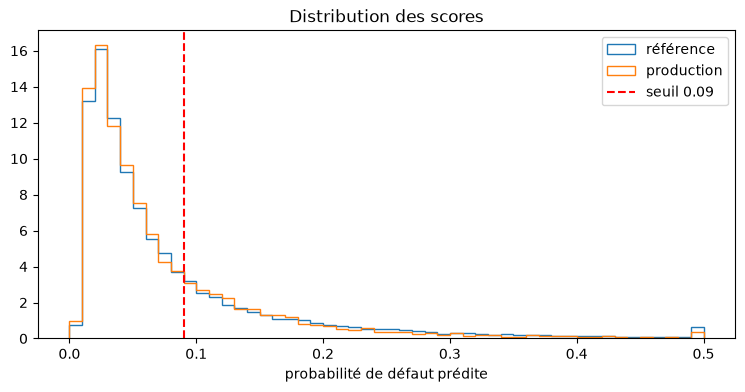

In [12]:
# Scores de référence : le modèle appliqué à 50 000 clients d'entraînement (les 800 variables)
X_ref = pd.read_parquet(RACINE / "data" / "reference.parquet", columns=modele.variables).sample(50_000, random_state=42)
scores = {
    "référence": pd.Series(modele.modele.predict_proba(X_ref)[:, 1]),
    "production": predictions["probabilite_defaut"],      # renvoyés par l'API et journalisés
}
del X_ref                                                  # libère ~1,5 Go de mémoire

display(pd.DataFrame({
    nom: {"score_moyen": s.mean(), "score_médian": s.median(), "taux_refus_%": (s >= modele.seuil).mean() * 100}
    for nom, s in scores.items()
}).T.round(4))
print("PSI des scores :", round(calculer_psi(scores["référence"], scores["production"]), 4))

fig, ax = plt.subplots(figsize=(9, 4))
tranches = np.linspace(0, 0.5, 51)
for nom, s in scores.items():
    ax.hist(s.clip(upper=0.5), bins=tranches, density=True, histtype="step", label=nom)
ax.axvline(modele.seuil, color="red", linestyle="--", label=f"seuil {modele.seuil}")
ax.set(xlabel="probabilité de défaut prédite", title="Distribution des scores")
ax.legend();

### Erreurs et latence

Les durées sont mesurées **dans l'API** : `duree_ms` couvre la requête entière côté serveur,
`duree_inference_ms` le seul calcul du modèle. La latence réseau, vue par le client, s'y ajoute.

In [13]:
# Taux d'erreur : la part de chaque statut HTTP
display(appels["statut_http"].value_counts().rename_axis("statut").to_frame("appels")
        .assign(part_pct=lambda d: (d["appels"] / len(appels) * 100).round(1)))

# Latence des prédictions réussies : médiane, p95, p99 (les moyennes cachent les appels lents)
reussis = appels[appels["statut_http"] == 200].copy()
reussis["duree_hors_inference_ms"] = reussis["duree_ms"] - reussis["duree_inference_ms"]
display(reussis[["duree_ms", "duree_inference_ms", "duree_hors_inference_ms"]]
        .describe(percentiles=[0.5, 0.95, 0.99]).round(2))

# Raisons des refus, lues dans la colonne JSON « erreur »
refus = appels.loc[appels["statut_http"] != 200, "erreur"]
display(pd.Series([f'{e["type"]} : {e["loc"][-1]}' for liste in refus for e in liste]).value_counts())

# Les appels les plus lents : à quel moment, et est-ce le modèle ou le reste ?
appels.nlargest(3, "duree_ms")[["id", "date_appel", "duree_ms", "duree_inference_ms"]]

,appels,part_pct
statut,,
200,4912,98.2
422,88,1.8


,duree_ms,duree_inference_ms,duree_hors_inference_ms
count,4912.00,4912.00,4912.00
mean,5.16,4.41,0.75
std,1.28,1.20,0.20
min,4.18,3.50,0.60
50%,5.05,4.34,0.71
95%,5.88,4.98,0.96
99%,6.89,5.79,1.33
max,59.33,58.44,7.49


missing : AMT_INCOME_TOTAL    88
Name: count, dtype: int64

,id,date_appel,duree_ms,duree_inference_ms
2071,2072,2026-10-30 10:29:14.318170,59.327125,58.438417
2167,2168,2026-10-30 10:29:14.997089,49.162000,47.743167
4745,4746,2026-10-30 10:29:31.719351,30.714375,27.618250


### Interprétation

**Les décisions n'ont pas changé.** Le PSI des scores est de 0,007 et le taux de refus passe de
27,2 % à 25,9 %. La dérive critique de `PAYMENT_RATE` ne se répercute pas sur les scores : elle ne
pèse que 2,9 % du gain du modèle, et les deux variables qui pèsent 30 % (`EXT_SOURCE_3`,
`EXT_SOURCE_2`) sont stables.

**Opérationnel : aucune anomalie.** 1,8 % d'erreurs, toutes des 422 dues à `AMT_INCOME_TOTAL`
absent : ce sont les requêtes invalidées exprès par la simulation, et l'API les refuse comme prévu.
La latence est stable (p99 6,9 ms), l'inférence représente 85 % du temps. Trois pics isolés
(30 à 59 ms) se produisent en milieu de série et viennent de l'inférence elle-même : probablement la
machine occupée à autre chose à cet instant. À surveiller seulement s'ils se répètent.

## 7. Suivi dans le temps et scénario de production dégradée

### La dérive est-elle progressive ou soudaine ?

On découpe les appels en **fenêtres de 1 000**, dans leur ordre d'arrivée, et on calcule le PSI de
chaque fenêtre. En production réelle, une fenêtre correspondrait à une période (jour, semaine) ;
ici, la simulation a envoyé 5 000 clients en 35 secondes, l'ordre d'arrivée en tient lieu.


1    25.2
2    25.5
3    25.7
4    26.0
5    27.4
Name: taux_refus_%, dtype: float64

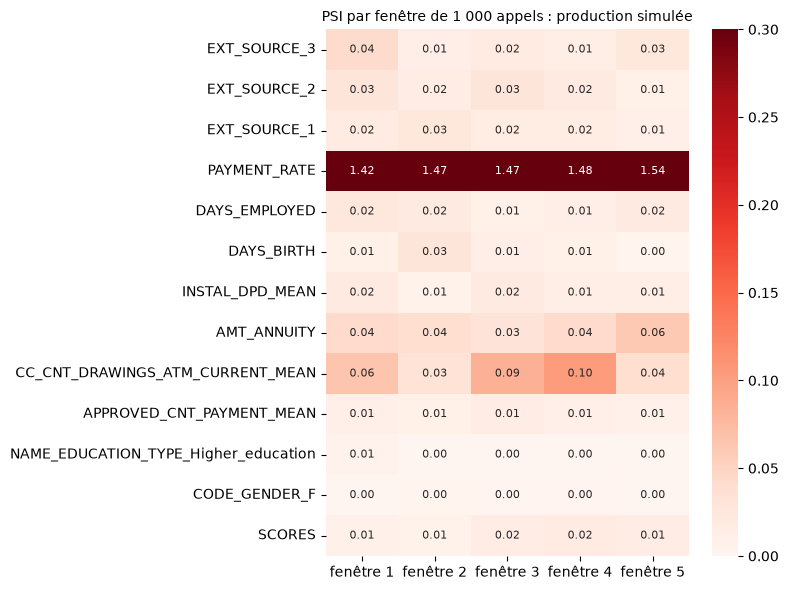

In [14]:
assert predictions["id"].is_monotonic_increasing          # production est dans l'ordre d'arrivée des appels
fenetres = np.arange(len(production)) // 1000 + 1          # 1 000 appels par fenêtre : 1, 2, 3, 4, 5 (912)


def suivre_par_fenetre(production, scores_production, titre):
    """Carte des PSI fenêtre par fenêtre : une ligne par variable surveillée, plus les scores."""
    suivi = {}
    for numero in np.unique(fenetres):
        dans_fenetre = fenetres == numero
        psi = {nom: calculer_psi(reference[nom], production.loc[dans_fenetre, nom]) for nom in VARIABLES_SUIVIES}
        psi["SCORES"] = calculer_psi(scores["référence"], scores_production[dans_fenetre])
        suivi[f"fenêtre {numero}"] = psi
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(pd.DataFrame(suivi), vmin=0, vmax=0.3, cmap="Reds", annot=True, fmt=".2f",
                annot_kws={"size": 8}, ax=ax)
    ax.set_title(titre, fontsize=10)
    fig.tight_layout()
    return fig


suivre_par_fenetre(production, scores["production"], "PSI par fenêtre de 1 000 appels : production simulée")
(scores["production"] >= modele.seuil).groupby(fenetres).mean().mul(100).round(1).rename("taux_refus_%")


In [15]:
def alertes(reference, production, scores_reference, scores_production):
    """La règle d'alerte de la section 5 : la liste des déclencheurs allumés."""
    declencheurs = []
    for nom in VARIABLES_SUIVIES:
        psi = calculer_psi(reference[nom], production[nom])
        if psi > 0.25:
            declencheurs.append(f"{nom} : PSI {psi:.2f}")
        ecart = (production[nom].isna().mean() - reference[nom].isna().mean()) * 100
        if abs(ecart) > 10:
            declencheurs.append(f"{nom} : manquants {ecart:+.1f} pts")
    psi_scores = calculer_psi(scores_reference, scores_production)
    ecart_refus = ((scores_production >= modele.seuil).mean() - (scores_reference >= modele.seuil).mean()) * 100
    if psi_scores > 0.1 or abs(ecart_refus) > 5:
        declencheurs.append(f"SCORES : PSI {psi_scores:.2f}, refus {ecart_refus:+.1f} pts")
    return declencheurs


def afficher_alertes(production, scores_production):
    for numero in np.unique(fenetres):
        dans_fenetre = fenetres == numero
        declencheurs = alertes(reference, production[dans_fenetre], scores["référence"], scores_production[dans_fenetre])
        print(f"fenêtre {numero} →", " | ".join(declencheurs) or "aucune alerte")


afficher_alertes(production, scores["production"])


fenêtre 1 → EXT_SOURCE_1 : manquants -13.4 pts | PAYMENT_RATE : PSI 1.42
fenêtre 2 → EXT_SOURCE_1 : manquants -13.7 pts | PAYMENT_RATE : PSI 1.47
fenêtre 3 → EXT_SOURCE_1 : manquants -13.0 pts | PAYMENT_RATE : PSI 1.47
fenêtre 4 → EXT_SOURCE_1 : manquants -14.1 pts | PAYMENT_RATE : PSI 1.48
fenêtre 5 → EXT_SOURCE_1 : manquants -13.7 pts | PAYMENT_RATE : PSI 1.54


### Scénario de production dégradée : la surveillance détecte-t-elle une dérive grave ?

La production réelle ne montre qu'une dérive sans effet sur les décisions. Pour vérifier que la
surveillance réagit quand c'est grave, on simule une panne réaliste : à partir de la fenêtre 3, le
fournisseur d'`EXT_SOURCE_3` (la variable la plus importante du modèle) change d'échelle, et ses
valeurs sont multipliées par 0,7. Les scores sont recalculés par le modèle sur les 800 variables,
pour mesurer l'effet réel sur les décisions. C'est l'équivalent d'un test unitaire de la surveillance.

fenêtre 1 → EXT_SOURCE_1 : manquants -13.4 pts | PAYMENT_RATE : PSI 1.42
fenêtre 2 → EXT_SOURCE_1 : manquants -13.7 pts | PAYMENT_RATE : PSI 1.47
fenêtre 3 → EXT_SOURCE_3 : PSI 4.25 | EXT_SOURCE_1 : manquants -13.0 pts | PAYMENT_RATE : PSI 1.47 | SCORES : PSI 0.07, refus +5.7 pts
fenêtre 4 → EXT_SOURCE_3 : PSI 4.16 | EXT_SOURCE_1 : manquants -14.1 pts | PAYMENT_RATE : PSI 1.48 | SCORES : PSI 0.06, refus +7.0 pts
fenêtre 5 → EXT_SOURCE_3 : PSI 4.13 | EXT_SOURCE_1 : manquants -13.7 pts | PAYMENT_RATE : PSI 1.54 | SCORES : PSI 0.08, refus +6.9 pts
Lot complet → ['EXT_SOURCE_3 : PSI 0.42', 'EXT_SOURCE_1 : manquants -13.6 pts', 'PAYMENT_RATE : PSI 1.47']


1    25.2
2    25.5
3    32.9
4    34.2
5    34.1
Name: taux_refus_%, dtype: float64

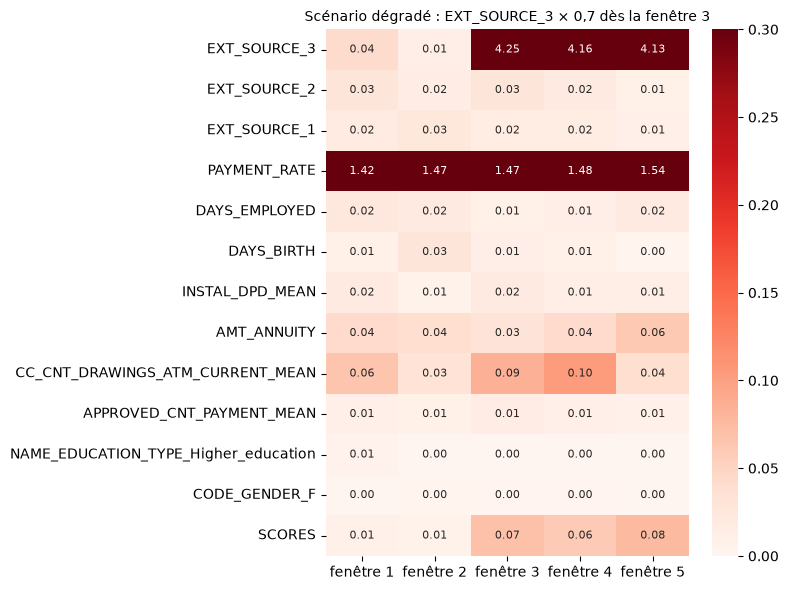

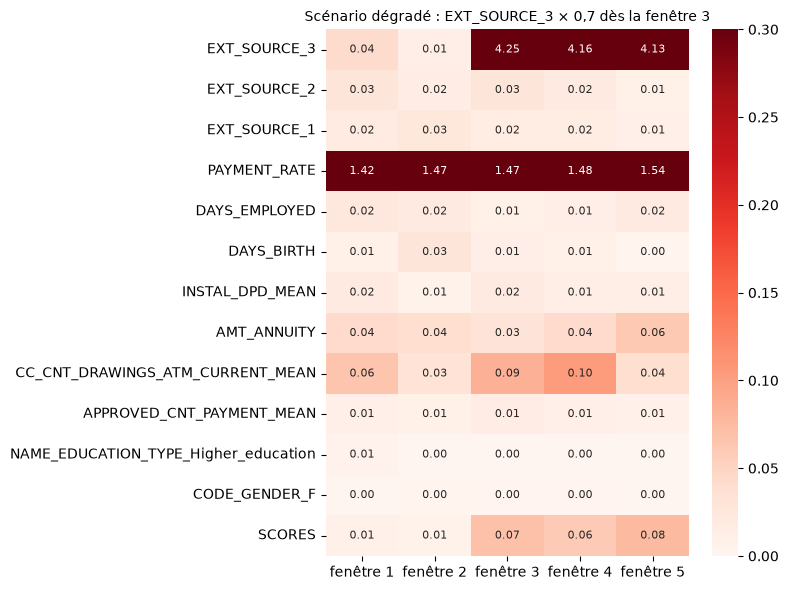

In [16]:
# Les 800 variables des clients envoyés à l'API, dans l'ordre des appels
X_prod = (pd.read_parquet(RACINE / "data" / "production.parquet")
          .set_index("SK_ID_CURR").loc[predictions["id_client"], modele.variables])

# Contrôle : recalculés ici, les scores sont bien ceux que l'API a renvoyés et journalisés
assert np.allclose(modele.modele.predict_proba(X_prod)[:, 1], predictions["probabilite_defaut"], atol=1e-4)

# Scénario : à partir de la fenêtre 3, le fournisseur d'EXT_SOURCE_3 change d'échelle (valeurs × 0,7)
X_prod.loc[fenetres >= 3, "EXT_SOURCE_3"] *= 0.7
production_degradee = X_prod[VARIABLES_SUIVIES].astype(float).set_axis(production.index)
scores_degrades = pd.Series(modele.modele.predict_proba(X_prod)[:, 1], index=production.index)
del X_prod

afficher_alertes(production_degradee, scores_degrades)
print("Lot complet →", alertes(reference, production_degradee, scores["référence"], scores_degrades))
display((scores_degrades >= modele.seuil).groupby(fenetres).mean().mul(100).round(1).rename("taux_refus_%"))
suivre_par_fenetre(production_degradee, scores_degrades, "Scénario dégradé : EXT_SOURCE_3 × 0,7 dès la fenêtre 3")


### Interprétation

**Production réelle : une dérive présente dès le début, et stable.** Le PSI de `PAYMENT_RATE`
reste entre 1,42 et 1,54 dans les cinq fenêtres, l'écart de manquants d'`EXT_SOURCE_1` entre −13 et
−14 points. Rien ne s'aggrave : la population était différente dès le premier appel. C'est le profil
d'un changement de population (nouvelle offre, nouvelle cible), pas d'une panne qui s'installe.

**Scénario dégradé : la surveillance réagit dès la fenêtre touchée.** Le PSI d'`EXT_SOURCE_3` passe
de 0,04 à 4,25, et le taux de refus de 25 % à 33-34 % : l'alerte sur les scores se déclenche dès la
fenêtre 3. Cette fois la dérive touche une variable qui pèse 16 % du gain, et les décisions changent.

**Sur le lot complet, l'alerte sur les scores ne se déclenche pas.** Les deux fenêtres saines
diluent les trois dégradées : le taux de refus global ne monte que de 3 points. C'est pourquoi la
surveillance se fait par fenêtre glissante, et pas sur l'ensemble de l'historique.